In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from pricing import price_option
from test_pricing import *
from simulation import *
from greeks import *

In [2]:
%matplotlib inline

In [3]:
S0 = 100; E = 100; r = 0.05; sig = 0.2; T = 1
omega = 1.8
tol = 1e-8

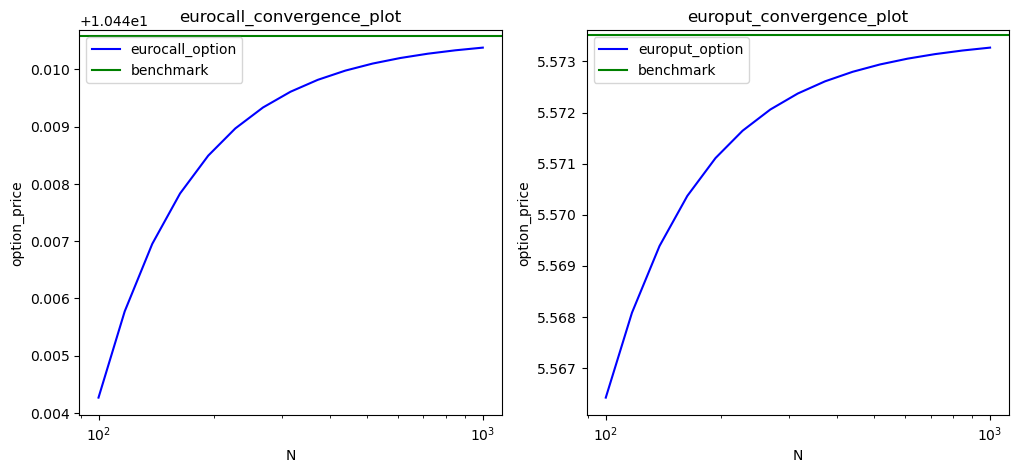

In [ ]:
#Convergence plot of eurocall option and europut option
N_values = np.logspace(2, 3, 15, dtype = int)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
Call = []
for N in N_values:
    Nt = 4 * N
    L = 1.5
    N1 = N
    N2 = N
    dx = L / N

    x = price_option(S0, E, r, sig, T, Nt, N1, N2, dx)
    Call.append(x)
Cmark = eurocallbenchmark(E, S0, r, sig, T)
ax[0].plot(N_values, Call, color = 'blue', label = 'eurocall_option')
ax[0].axhline(y = Cmark, color = 'green', label = 'benchmark')
ax[0].legend()
ax[0].set_title('eurocall_convergence_plot')
ax[0].set_xlabel('N')
ax[0].set_ylabel('option_price')
ax[0].set_xscale('log')

Put = []
for N in N_values:
    Nt = 4 * N
    L = 1.5
    N1 = N
    N2 = N
    dx = L / N

    x = price_option(S0, E, r, sig, T, Nt, N1, N2, dx,
                    option_type='put')
    Put.append(x)
Pmark = europutbenchmark(E, S0, r, sig, T)
ax[1].plot(N_values, Put, color = 'blue', label = 'europut_option')
ax[1].axhline(y = Pmark, color = 'green', label = 'benchmark')
ax[1].legend()
ax[1].set_title('europut_convergence_plot')
ax[1].set_xlabel('N')
ax[1].set_ylabel('option_price')
ax[1].set_xscale('log')

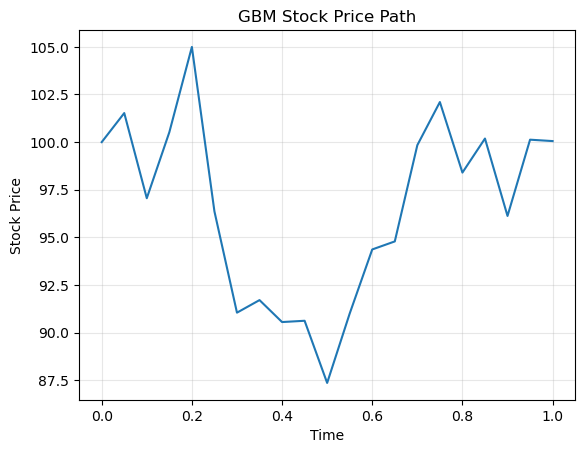

In [4]:
S0 = 100; E = 100; r = 0.05; sig = 0.2; T = 1; Nt = 20
N1 = 40; N2 = 40; dx = 0.04
omega = 1.8
tol = 1e-8
h = 1e-3

S = simulate_gbw(S0, r, sig, T, Nt, 1, seed=42)[0]
t = np.linspace(0, T, Nt + 1)

plt.plot(t, S)
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.title("GBM Stock Price Path")
plt.grid(alpha=0.3)
plt.show()

In [5]:
args = (S, E, r, sig, T, Nt, N1, N2, dx, omega, tol)

D = np.array(delta(*args))
G = np.array(gamma(*args))
Th = np.array(theta(*args))

Ve = np.array(vega(S, E, r, sig, T, h, Nt, N1, N2, dx, omega, tol))

Rh = np.array(rho(S, E, r, sig, T, h, Nt, N1, N2, dx, omega, tol))

In [6]:
q = T - t[:-1]
s = S[:-1]

d1 = (np.log(s/E) + (r + sig**2/2)*q) / (sig*np.sqrt(q))
d2 = d1 - sig*np.sqrt(q)

D_bs = norm.cdf(d1)
G_bs = norm.pdf(d1) / (s*sig*np.sqrt(q))
Th_bs = (-s*norm.pdf(d1)*sig/(2*np.sqrt(q))
        -r*E*np.exp(-r*q)*norm.cdf(d2))
Ve_bs = s*norm.pdf(d1)*np.sqrt(q)
Rh_bs = E*q*np.exp(-r*q)*norm.cdf(d2)

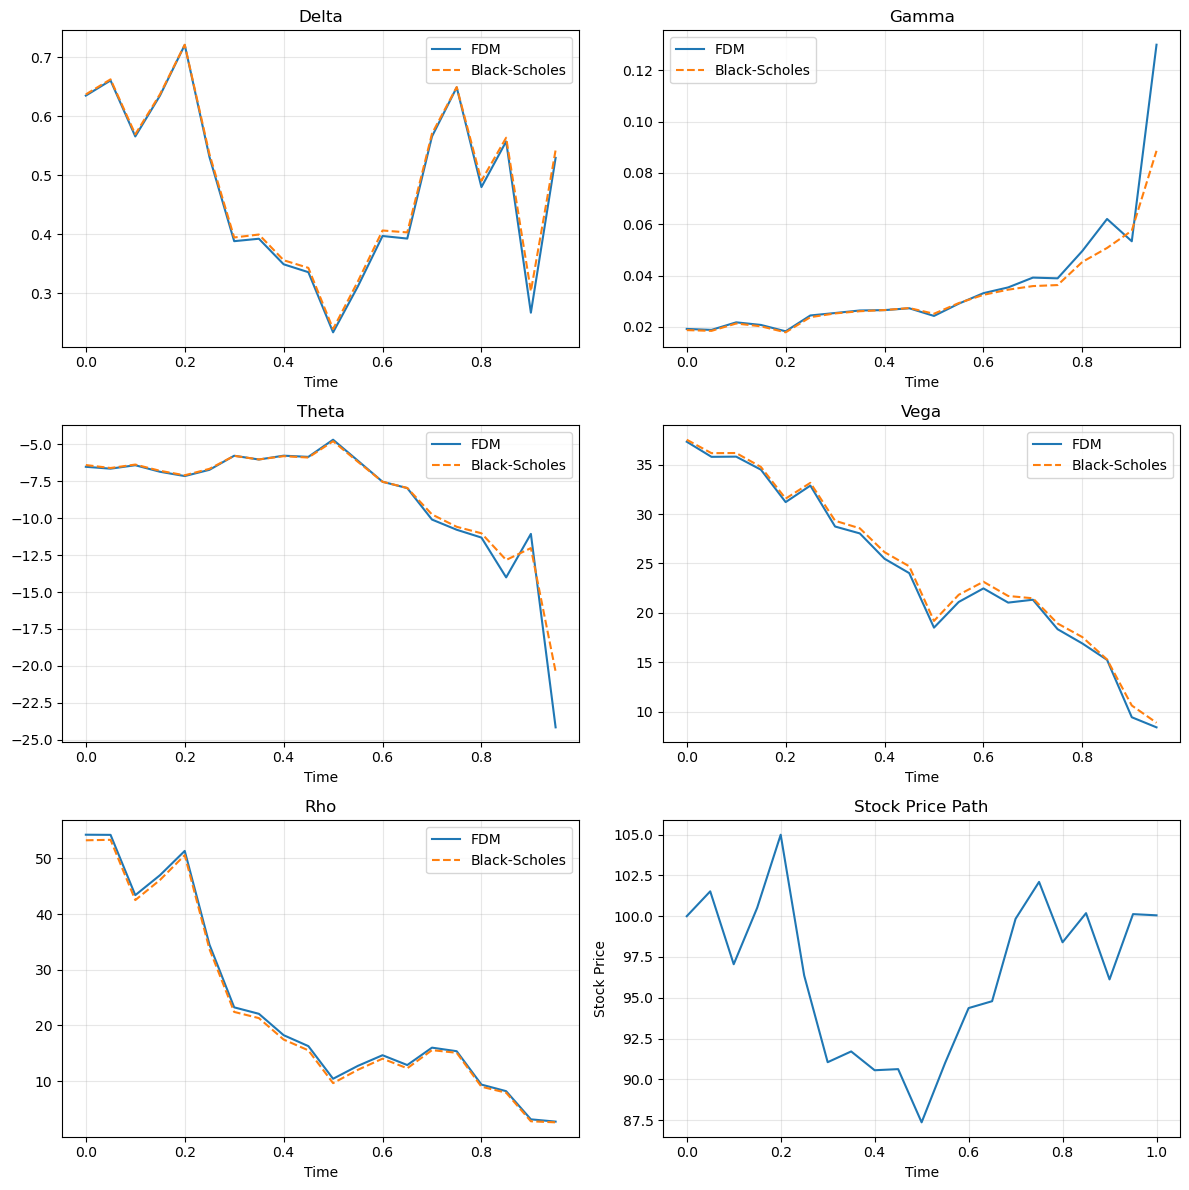

In [7]:
fdm = [D[:-1], G[:-1], Th[:-1], Ve[:-1], Rh[:-1]]
benchmarks = [D_bs, G_bs, Th_bs, Ve_bs, Rh_bs]
names = ["Delta", "Gamma", "Theta", "Vega", "Rho"]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, name, y, benchmark in zip(axes.flat, names, fdm, benchmarks):
    ax.plot(t[:-1], y, label="FDM")
    ax.plot(t[:-1], benchmark, "--", label="Black-Scholes")
    ax.set_title(name)
    ax.set_xlabel("Time")
    ax.legend()
    ax.grid(alpha=0.3)

axes.flat[-1].plot(t, S)
axes.flat[-1].set_title("Stock Price Path")
axes.flat[-1].set_xlabel("Time")
axes.flat[-1].set_ylabel("Stock Price")
axes.flat[-1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
rmse = np.array([np.sqrt(np.mean((y - benchmark)**2))
    for y, benchmark in zip(fdm, benchmarks)])

print(dict(zip(names, rmse)))

{'Delta': np.float64(0.01051858441234694), 'Gamma': np.float64(0.00972603918698962), 'Theta': np.float64(0.9169833046808057), 'Vega': np.float64(0.566499080051358), 'Rho': np.float64(0.6884407018134863)}


In [3]:
S0 = 100; E = 100; r = 0.05; sig = 0.2; T = 1; Nt = 200; 
N1 = 150; N2 = 150; dx = 0.01
omega = 1.5
tol = 1e-8

AM = option_grid(S0, E, r, sig, T, Nt, 
                 N1, N2, dx, omega, tol,
                 option_type = 'put',
                 option_style = 'american')
s1 = simulate_s(S0, E, N1, N2, dx, 
                 option_style = 'american')

In [4]:
S0 = 100; E = 100; r = 0.05; sig = 0.2; T = 1
Nt = 200
omega = 1.5
tol = 1e-8
dx = 0.01

N1 = 180; N2 = 40; barrier = 120
UOC = option_grid(S0, E, r, sig, T, Nt, 
                 N1, N2, dx, omega, tol,
                 option_type = 'call',
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'up_and_out')
s2 = simulate_s(S0, E, N1, N2, dx, 
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'up_and_out')

UIC = option_grid(S0, E, r, sig, T, Nt, 
                 N1, N2, dx, omega, tol,
                 option_type = 'call',
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'up_and_in')
s3 = simulate_s(S0, E, N1, N2, dx, 
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'up_and_in')

N1 = 40; N2 = 180; barrier = 80
DOC = option_grid(S0, E, r, sig, T, Nt, 
                 N1, N2, dx, omega, tol,
                 option_type = 'call',
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'down_and_out')
s4 = simulate_s(S0, E, N1, N2, dx, 
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'down_and_out')

DIC = option_grid(S0, E, r, sig, T, Nt, 
                 N1, N2, dx, omega, tol,
                 option_type = 'call',
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'down_and_in')
s5 = simulate_s(S0, E, N1, N2, dx, 
                 option_style = 'barrier',
                 barrier = barrier,
                 barrier_type = 'down_and_in')

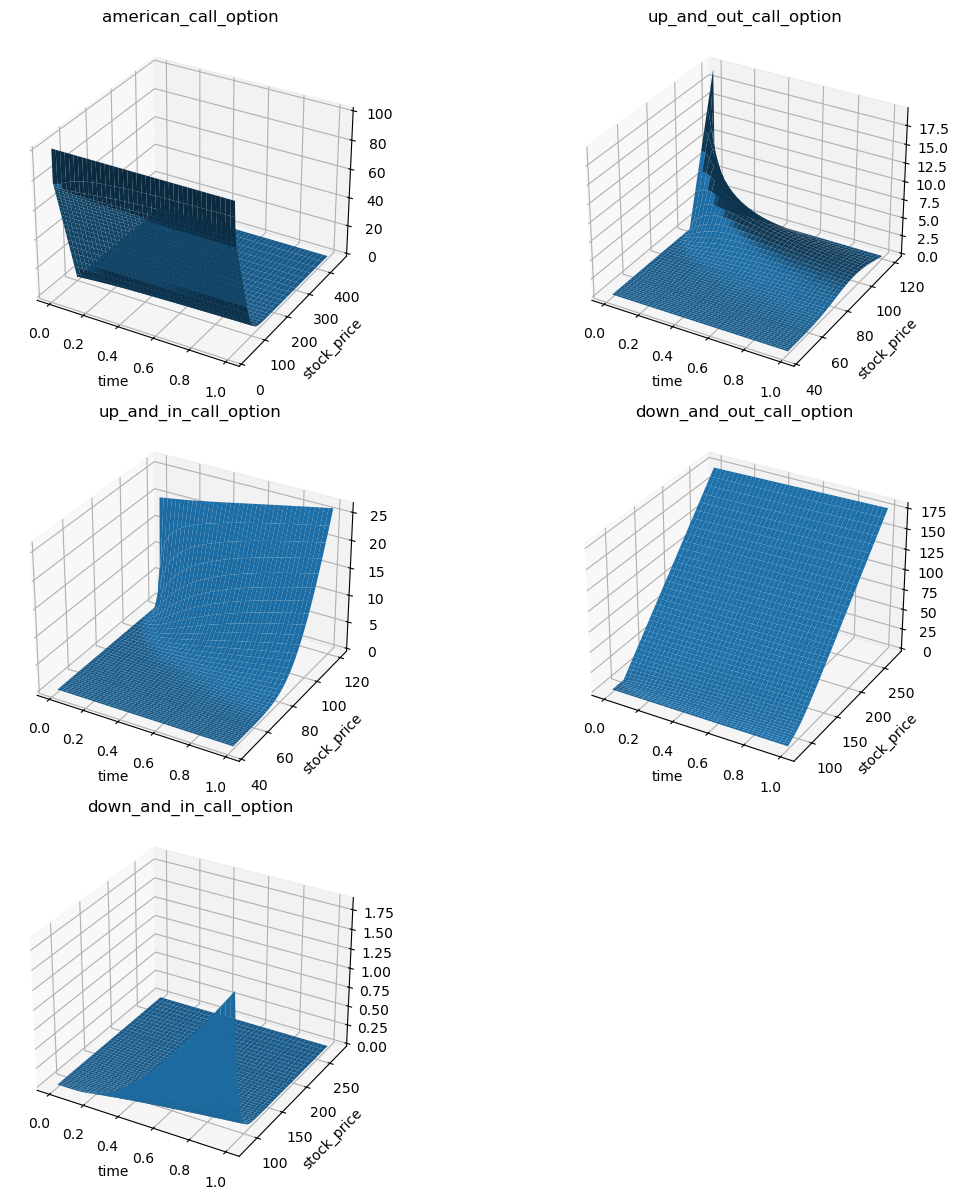

In [8]:
FDM = [AM, UOC, UIC, DOC, DIC]
name = ['american_call_option', 'up_and_out_call_option', 
        'up_and_in_call_option', 'down_and_out_call_option',
        'down_and_in_call_option']
Sgrid = [s1, s2, s3, s4, s5]
tgrid = np.linspace(0, T, Nt + 1)

fig, axes = plt.subplots(3, 2, figsize = (12, 12), subplot_kw={'projection': '3d'})

for ax, U, name, sgrid in zip(axes.flatten(), FDM, name, Sgrid):
    tt, ss = np.meshgrid(tgrid, sgrid)
    ax.plot_surface(tt, ss, U)
    ax.set_xlabel('time')
    ax.set_ylabel('stock_price')
    ax.set_title(name)

axes.flatten()[-1].remove()

plt.tight_layout()
plt.show()
